In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path("/home/bannanakid/RCRL_on_RCMDP")
sys.path.insert(0, str(PROJECT))

from envs.half_cheetah_jointspeed_cost import HalfCheetahJointSpeedCost
from configs.halfcheetah_safety_thresholds import JOINT_SPEED_THRESHOLDS, JOINT_SPEED_SCALES, COST_VERSION

JOINT_NAMES = (
    "back_thigh",
    "back_shin",
    "back_foot",
    "front_thigh",
    "front_shin",
    "front_foot",
)

RUN = 1
FIRST_SEED = 1005
EPISODES = 50
EVALUATE_FREQ = 25

UNCONSTRAINED_ACTOR_PATH = PROJECT / "models" / "HalfCheetahUnconstrained" / f"run{RUN}" / "Best_Unconstrained_actor"
JOINT_ACTOR_PATH = PROJECT / "models" / "HalfCheetahJointSpeedCost" / f"run{RUN}" / "Best_JointSpeedCost_actor"
OUTPUT = PROJECT / "plot_data" / "HalfCheetahJointSpeedCost" / f"run{RUN}" / "evaluation"
OUTPUT.mkdir(parents=True, exist_ok=True)

joint_thresholds = np.asarray(JOINT_SPEED_THRESHOLDS, dtype=np.float64)
joint_scales = np.asarray(JOINT_SPEED_SCALES, dtype=np.float64)

print("Project:", PROJECT)
print("Joint-speed thresholds:", joint_thresholds)
print("Joint-speed scales:", joint_scales)
print("Cost version:", COST_VERSION)
print("Held-out seeds:", FIRST_SEED, "through", FIRST_SEED + EPISODES - 1)
print("Unconstrained actor:", UNCONSTRAINED_ACTOR_PATH)
print("Joint-speed actor:", JOINT_ACTOR_PATH)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Project: /home/bannanakid/RCRL_on_RCMDP
Joint-speed thresholds: [23.9524427  21.27392078 20.86986086 27.17251927 21.15867917 16.23436639]
Joint-speed scales: [23.9524427  21.27392078 20.86986086 27.17251927 21.15867917 16.23436639]
Cost version: behavior_inversion_15step_v2
Held-out seeds: 1005 through 1054
Unconstrained actor: /home/bannanakid/RCRL_on_RCMDP/models/HalfCheetahUnconstrained/run1/Best_Unconstrained_actor
Joint-speed actor: /home/bannanakid/RCRL_on_RCMDP/models/HalfCheetahJointSpeedCost/run1/Best_JointSpeedCost_actor


In [2]:
if JOINT_SPEED_THRESHOLDS is None or JOINT_SPEED_SCALES is None:
    raise RuntimeError("JOINT_SPEED_THRESHOLDS and JOINT_SPEED_SCALES must be finalized before evaluation")

if joint_thresholds.shape != (6,) or joint_scales.shape != (6,):
    raise RuntimeError("Joint-speed thresholds and scales must each contain six values")

if np.any(joint_scales <= 0):
    raise RuntimeError("Joint-speed scales must all be positive")

if not UNCONSTRAINED_ACTOR_PATH.exists():
    raise FileNotFoundError(UNCONSTRAINED_ACTOR_PATH)

if not JOINT_ACTOR_PATH.exists():
    raise FileNotFoundError(
        f"{JOINT_ACTOR_PATH}\nNo feasible Best_JointSpeedCost_actor was found. Check the joint-speed training evaluation outputs."
    )

print("Both actor files found")

Both actor files found


In [3]:
class ActorGaussian(nn.Module):
    def __init__(self, state_dim, hidden_width, action_dim, max_action):
        super().__init__()
        self.max_action = float(max_action)
        self.fc1 = nn.Linear(state_dim, hidden_width)
        self.fc2 = nn.Linear(hidden_width, hidden_width)
        self.fc3 = nn.Linear(hidden_width, hidden_width)
        self.mean_layer = nn.Linear(hidden_width, action_dim)
        self.log_std = nn.Parameter(torch.zeros(1, action_dim))
        self.activate_func = nn.ReLU()

    def forward(self, state):
        state = self.activate_func(self.fc1(state))
        state = self.activate_func(self.fc2(state))
        state = self.activate_func(self.fc3(state))
        return self.max_action * torch.tanh(self.mean_layer(state))


def unwrap_reset(reset_result):
    result = reset_result
    while isinstance(result, tuple):
        result = result[0]
    return np.asarray(result, dtype=np.float64)


def load_actor(path, env):
    state = torch.load(path, map_location="cpu")

    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]

    if isinstance(state, dict) and "actor_state_dict" in state:
        state = state["actor_state_dict"]

    actor = ActorGaussian(
        int(state["fc1.weight"].shape[1]),
        int(state["fc1.weight"].shape[0]),
        int(state["mean_layer.weight"].shape[0]),
        float(env.action_space.high[0]),
    )

    actor.load_state_dict(state)
    actor.eval()
    return actor

In [4]:
probe_env = HalfCheetahJointSpeedCost()

unconstrained_actor = load_actor(UNCONSTRAINED_ACTOR_PATH, probe_env)
joint_actor = load_actor(JOINT_ACTOR_PATH, probe_env)

print("Observation dimension:", probe_env.observation_space.shape[0])
print("Action dimension:", probe_env.action_space.shape[0])
print("Unconstrained parameters:", sum(p.numel() for p in unconstrained_actor.parameters()))
print("Joint-speed parameters:", sum(p.numel() for p in joint_actor.parameters()))

/home/bannanakid/miniforge3/envs/rcrl/lib/python3.10/site-packages/gym/envs/mujoco/mujoco_env.py:190: UserWarning: WARN: This version of the mujoco environments depends on the mujoco-py bindings, which are no longer maintained and may stop working. Please upgrade to the v4 versions of the environments (which depend on the mujoco python bindings instead), unless you are trying to precisely replicate previous works).
  logger.warn(


Observation dimension: 18
Action dimension: 6
Unconstrained parameters: 9932
Joint-speed parameters: 9932


In [5]:
def collect_policy(actor, label, first_seed, episodes):
    env = HalfCheetahJointSpeedCost()

    episode = []
    reset_seed = []
    step = []
    reward = []
    cost = []
    xpos = []
    joint_velocities = []
    joint_speeds = []
    joint_excess = []
    joint_normalized_excess = []
    maximum_joint_speed = []
    fastest_joint_index = []
    actions = []
    maximum_action_abs = []

    episode_rewards = []
    episode_costs = []
    episode_max_costs = []
    episode_lengths = []
    episode_net_displacements = []
    episode_absolute_displacements = []
    episode_traveled_distances = []

    for ep in range(episodes):
        ep_seed = first_seed + ep
        obs = unwrap_reset(env.reset(seed=ep_seed))

        start_x = float(env.sim.data.qpos[0])
        previous_x = start_x

        total_reward = 0.0
        total_cost = 0.0
        max_cost = 0.0
        traveled = 0.0
        t = 0
        done = False

        while not done:
            x = torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)

            with torch.no_grad():
                action = actor(x).cpu().numpy().reshape(-1)

            action = np.clip(action, env.action_space.low, env.action_space.high)
            obs_next, r, c, truncated, terminated, info = env.step(action)
            done = bool(truncated or terminated)

            current_x = float(info.get("xpos", env.sim.data.qpos[0]))
            velocities = np.asarray(
                info.get("joint_velocities", env.sim.data.qvel[3:9]),
                dtype=np.float64,
            ).copy()
            speeds = np.asarray(
                info.get("joint_speeds", np.abs(velocities)),
                dtype=np.float64,
            ).copy()
            excess = np.maximum(speeds - joint_thresholds, 0.0)
            normalized_excess = excess / joint_scales
            fastest = int(np.argmax(speeds))

            traveled += abs(current_x - previous_x)
            previous_x = current_x

            episode.append(ep + 1)
            reset_seed.append(ep_seed)
            step.append(t)
            reward.append(float(r))
            cost.append(float(c))
            xpos.append(current_x)
            joint_velocities.append(velocities)
            joint_speeds.append(speeds)
            joint_excess.append(excess)
            joint_normalized_excess.append(normalized_excess)
            maximum_joint_speed.append(float(np.max(speeds)))
            fastest_joint_index.append(fastest)
            actions.append(np.asarray(action, dtype=np.float64).copy())
            maximum_action_abs.append(float(np.max(np.abs(action))))

            total_reward += float(r)
            total_cost += float(c)
            max_cost = max(max_cost, float(c))

            obs = obs_next
            t += 1

        end_x = float(env.sim.data.qpos[0])

        episode_rewards.append(total_reward)
        episode_costs.append(total_cost)
        episode_max_costs.append(max_cost)
        episode_lengths.append(t)
        episode_net_displacements.append(end_x - start_x)
        episode_absolute_displacements.append(abs(end_x - start_x))
        episode_traveled_distances.append(traveled)

        print(
            f"{label}: episode {ep + 1}/{episodes} seed={ep_seed} "
            f"reward={total_reward:.3f} total_cost={total_cost:.6f} max_cost={max_cost:.6f}"
        )

    return {
        "label": label,
        "episode": np.asarray(episode, dtype=np.int64),
        "reset_seed": np.asarray(reset_seed, dtype=np.int64),
        "step": np.asarray(step, dtype=np.int64),
        "reward": np.asarray(reward, dtype=np.float64),
        "cost": np.asarray(cost, dtype=np.float64),
        "xpos": np.asarray(xpos, dtype=np.float64),
        "joint_velocities": np.asarray(joint_velocities, dtype=np.float64),
        "joint_speeds": np.asarray(joint_speeds, dtype=np.float64),
        "joint_excess": np.asarray(joint_excess, dtype=np.float64),
        "joint_normalized_excess": np.asarray(joint_normalized_excess, dtype=np.float64),
        "maximum_joint_speed": np.asarray(maximum_joint_speed, dtype=np.float64),
        "fastest_joint_index": np.asarray(fastest_joint_index, dtype=np.int64),
        "actions": np.asarray(actions, dtype=np.float64),
        "maximum_action_abs": np.asarray(maximum_action_abs, dtype=np.float64),
        "episode_rewards": np.asarray(episode_rewards, dtype=np.float64),
        "episode_costs": np.asarray(episode_costs, dtype=np.float64),
        "episode_max_costs": np.asarray(episode_max_costs, dtype=np.float64),
        "episode_lengths": np.asarray(episode_lengths, dtype=np.int64),
        "episode_net_displacements": np.asarray(episode_net_displacements, dtype=np.float64),
        "episode_absolute_displacements": np.asarray(episode_absolute_displacements, dtype=np.float64),
        "episode_traveled_distances": np.asarray(episode_traveled_distances, dtype=np.float64),
    }

In [6]:
unconstrained = collect_policy(
    unconstrained_actor,
    "Unconstrained",
    FIRST_SEED,
    EPISODES,
)

joint_constrained = collect_policy(
    joint_actor,
    "Joint-speed constrained",
    FIRST_SEED,
    EPISODES,
)

Unconstrained: episode 1/50 seed=1005 reward=1405.794 total_cost=6.242029 max_cost=0.278517
Unconstrained: episode 2/50 seed=1006 reward=1589.109 total_cost=0.756181 max_cost=0.117693
Unconstrained: episode 3/50 seed=1007 reward=1873.518 total_cost=0.563422 max_cost=0.100546
Unconstrained: episode 4/50 seed=1008 reward=1797.887 total_cost=0.782781 max_cost=0.192311
Unconstrained: episode 5/50 seed=1009 reward=1668.041 total_cost=2.559982 max_cost=0.211126
Unconstrained: episode 6/50 seed=1010 reward=1946.581 total_cost=0.899793 max_cost=0.144124
Unconstrained: episode 7/50 seed=1011 reward=1257.565 total_cost=20.618952 max_cost=0.392513
Unconstrained: episode 8/50 seed=1012 reward=1903.794 total_cost=0.691199 max_cost=0.232740
Unconstrained: episode 9/50 seed=1013 reward=1697.558 total_cost=2.876961 max_cost=0.184243
Unconstrained: episode 10/50 seed=1014 reward=1292.033 total_cost=1.883610 max_cost=0.289976
Unconstrained: episode 11/50 seed=1015 reward=1707.212 total_cost=1.666597 max

In [7]:
def save_dataset(data, path):
    np.savez_compressed(
        path,
        episode=data["episode"],
        reset_seed=data["reset_seed"],
        step=data["step"],
        reward=data["reward"],
        cost=data["cost"],
        xpos=data["xpos"],
        joint_velocities=data["joint_velocities"],
        joint_speeds=data["joint_speeds"],
        joint_excess=data["joint_excess"],
        joint_normalized_excess=data["joint_normalized_excess"],
        maximum_joint_speed=data["maximum_joint_speed"],
        fastest_joint_index=data["fastest_joint_index"],
        actions=data["actions"],
        maximum_action_abs=data["maximum_action_abs"],
        episode_rewards=data["episode_rewards"],
        episode_costs=data["episode_costs"],
        episode_max_costs=data["episode_max_costs"],
        episode_lengths=data["episode_lengths"],
        episode_net_displacements=data["episode_net_displacements"],
        episode_absolute_displacements=data["episode_absolute_displacements"],
        episode_traveled_distances=data["episode_traveled_distances"],
        joint_names=np.asarray(JOINT_NAMES),
        joint_speed_thresholds=joint_thresholds,
        joint_speed_scales=joint_scales,
        cost_version=np.asarray(str(COST_VERSION)),
        first_seed=np.asarray(FIRST_SEED, dtype=np.int64),
        number_of_episodes=np.asarray(EPISODES, dtype=np.int64),
    )


save_dataset(
    unconstrained,
    OUTPUT / "unconstrained_on_joint_speed_env.npz",
)

save_dataset(
    joint_constrained,
    OUTPUT / "joint_speed_constrained_evaluation.npz",
)

print("Saved:", OUTPUT / "unconstrained_on_joint_speed_env.npz")
print("Saved:", OUTPUT / "joint_speed_constrained_evaluation.npz")

Saved: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahJointSpeedCost/run1/evaluation/unconstrained_on_joint_speed_env.npz
Saved: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahJointSpeedCost/run1/evaluation/joint_speed_constrained_evaluation.npz


In [8]:
def longest_true_run(values):
    best = 0
    current = 0

    for value in values:
        if value:
            current += 1
            best = max(best, current)
        else:
            current = 0

    return best


def violation_events(values):
    values = np.asarray(values, dtype=bool)

    if len(values) == 0:
        return 0

    return int(values[0]) + int(np.sum(values[1:] & ~values[:-1]))


def overall_episode_violation_arrays(data):
    max_runs = []
    events = []
    violated = []

    for ep in np.unique(data["episode"]):
        mask = data["episode"] == ep
        flags = np.any(data["joint_speeds"][mask] > joint_thresholds, axis=1)

        max_runs.append(longest_true_run(flags))
        events.append(violation_events(flags))
        violated.append(bool(np.any(flags)))

    return (
        np.asarray(max_runs, dtype=np.int64),
        np.asarray(events, dtype=np.int64),
        np.asarray(violated, dtype=bool),
    )


def per_joint_episode_violation_frequency(data):
    result = []

    for joint_index in range(6):
        violated = []

        for ep in np.unique(data["episode"]):
            mask = data["episode"] == ep
            flags = data["joint_speeds"][mask, joint_index] > joint_thresholds[joint_index]
            violated.append(bool(np.any(flags)))

        result.append(float(np.mean(violated)))

    return np.asarray(result, dtype=np.float64)

In [9]:
def summarize_policy(data):
    speeds = data["joint_speeds"]
    flags = speeds > joint_thresholds
    any_flags = np.any(flags, axis=1)

    max_runs, events, violated = overall_episode_violation_arrays(data)

    return {
        "mean_episode_reward": float(np.mean(data["episode_rewards"])),
        "std_episode_reward": float(np.std(data["episode_rewards"])),
        "median_episode_reward": float(np.median(data["episode_rewards"])),
        "mean_episode_total_cost": float(np.mean(data["episode_costs"])),
        "median_episode_total_cost": float(np.median(data["episode_costs"])),
        "maximum_one_step_cost": float(np.max(data["cost"])),
        "overall_step_violation_rate": float(np.mean(any_flags)),
        "overall_episode_violation_frequency": float(np.mean(violated)),
        "longest_violation_run": int(np.max(max_runs)),
        "mean_longest_violation_run": float(np.mean(max_runs)),
        "mean_violation_events_per_episode": float(np.mean(events)),
        "mean_maximum_joint_speed": float(np.mean(data["maximum_joint_speed"])),
        "maximum_joint_speed": float(np.max(data["maximum_joint_speed"])),
        "mean_net_displacement": float(np.mean(data["episode_net_displacements"])),
        "mean_absolute_displacement": float(np.mean(data["episode_absolute_displacements"])),
        "mean_traveled_distance": float(np.mean(data["episode_traveled_distances"])),
        "mean_maximum_action_abs": float(np.mean(data["maximum_action_abs"])),
    }


unconstrained_summary = summarize_policy(unconstrained)
joint_summary = summarize_policy(joint_constrained)

summary = pd.DataFrame(
    {
        "Unconstrained": unconstrained_summary,
        "Joint-speed constrained": joint_summary,
    }
)

display(summary)

,Unconstrained,Joint-speed constrained
mean_episode_reward,1503.047712,1195.282592
std_episode_reward,419.860242,97.815421
median_episode_reward,1639.907033,1215.122516
mean_episode_total_cost,3.832063,0.571233
median_episode_total_cost,2.000058,0.155914
maximum_one_step_cost,0.570787,0.360013
overall_step_violation_rate,0.053660,0.009120
overall_episode_violation_frequency,1.000000,0.860000
longest_violation_run,4.000000,2.000000
mean_longest_violation_run,2.640000,1.120000


In [10]:
comparison = summary.copy()

reference = comparison["Unconstrained"].astype(float)
candidate = comparison["Joint-speed constrained"].astype(float)

comparison["Absolute change"] = candidate - reference
comparison["Percent change"] = np.where(
    np.abs(reference) > 1e-12,
    100.0 * (candidate - reference) / np.abs(reference),
    np.nan,
)

comparison.to_csv(OUTPUT / "summary.csv")
display(comparison)

print("Saved:", OUTPUT / "summary.csv")

,Unconstrained,Joint-speed constrained,Absolute change,Percent change
mean_episode_reward,1503.047712,1195.282592,-307.765120,-20.476071
std_episode_reward,419.860242,97.815421,-322.044821,-76.702862
median_episode_reward,1639.907033,1215.122516,-424.784517,-25.902963
mean_episode_total_cost,3.832063,0.571233,-3.260830,-85.093333
median_episode_total_cost,2.000058,0.155914,-1.844144,-92.204534
maximum_one_step_cost,0.570787,0.360013,-0.210774,-36.926957
overall_step_violation_rate,0.053660,0.009120,-0.044540,-83.004100
overall_episode_violation_frequency,1.000000,0.860000,-0.140000,-14.000000
longest_violation_run,4.000000,2.000000,-2.000000,-50.000000
mean_longest_violation_run,2.640000,1.120000,-1.520000,-57.575758


Saved: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahJointSpeedCost/run1/evaluation/summary.csv


In [11]:
def reduction(before, after):
    if abs(before) <= 1e-12:
        return np.nan
    return 100.0 * (before - after) / abs(before)


reward_retention = (
    100.0
    * joint_summary["mean_episode_reward"]
    / unconstrained_summary["mean_episode_reward"]
)

step_violation_reduction = reduction(
    unconstrained_summary["overall_step_violation_rate"],
    joint_summary["overall_step_violation_rate"],
)

episode_violation_reduction = reduction(
    unconstrained_summary["overall_episode_violation_frequency"],
    joint_summary["overall_episode_violation_frequency"],
)

total_cost_reduction = reduction(
    unconstrained_summary["mean_episode_total_cost"],
    joint_summary["mean_episode_total_cost"],
)

max_cost_reduction = reduction(
    unconstrained_summary["maximum_one_step_cost"],
    joint_summary["maximum_one_step_cost"],
)

print(f"Reward retention: {reward_retention:.2f}%")
print(f"Overall step violation reduction: {step_violation_reduction:.2f}%")
print(f"Overall episode violation-frequency reduction: {episode_violation_reduction:.2f}%")
print(f"Mean episode joint-speed-cost reduction: {total_cost_reduction:.2f}%")
print(f"Maximum one-step cost reduction: {max_cost_reduction:.2f}%")

Reward retention: 79.52%
Overall step violation reduction: 83.00%
Overall episode violation-frequency reduction: 14.00%
Mean episode joint-speed-cost reduction: 85.09%
Maximum one-step cost reduction: 36.93%


In [12]:
def per_joint_statistics(data):
    speeds = data["joint_speeds"]
    step_rates = np.mean(speeds > joint_thresholds, axis=0)
    episode_rates = per_joint_episode_violation_frequency(data)

    rows = []

    for i, name in enumerate(JOINT_NAMES):
        rows.append(
            {
                "joint": name,
                "threshold": joint_thresholds[i],
                "mean": float(np.mean(speeds[:, i])),
                "median": float(np.median(speeds[:, i])),
                "p95": float(np.percentile(speeds[:, i], 95)),
                "p99": float(np.percentile(speeds[:, i], 99)),
                "maximum": float(np.max(speeds[:, i])),
                "step_violation_rate": float(step_rates[i]),
                "episode_violation_frequency": float(episode_rates[i]),
            }
        )

    return pd.DataFrame(rows)


unconstrained_joint_stats = per_joint_statistics(unconstrained)
constrained_joint_stats = per_joint_statistics(joint_constrained)

unconstrained_joint_stats.insert(1, "policy", "Unconstrained")
constrained_joint_stats.insert(1, "policy", "Joint-speed constrained")

joint_stats = pd.concat(
    [unconstrained_joint_stats, constrained_joint_stats],
    ignore_index=True,
)

joint_stats.to_csv(OUTPUT / "per_joint_statistics.csv", index=False)
display(joint_stats)

print("Saved:", OUTPUT / "per_joint_statistics.csv")

,joint,policy,threshold,mean,median,p95,p99,maximum,step_violation_rate,episode_violation_frequency
0,back_thigh,Unconstrained,23.952443,8.576333,7.918174,20.921308,23.762266,29.536739,0.00896,0.98
1,back_shin,Unconstrained,21.273921,7.311740,6.684327,17.145523,21.096232,30.192995,0.00932,1.00
2,back_foot,Unconstrained,20.869861,5.666121,4.156602,16.759751,20.740576,28.697966,0.00890,0.92
3,front_thigh,Unconstrained,27.172519,10.193968,9.472210,23.214526,26.954977,32.979598,0.00918,0.86
4,front_shin,Unconstrained,21.158679,6.181809,5.288353,15.306667,21.117027,33.235771,0.00986,0.68
5,front_foot,Unconstrained,16.234366,6.059782,5.435812,14.098963,16.289236,23.780053,0.01064,0.94
6,back_thigh,Joint-speed constrained,23.952443,9.245468,9.502744,19.888519,21.057052,25.098805,0.00004,0.04
7,back_shin,Joint-speed constrained,21.273921,7.961303,7.587828,17.354697,19.368235,22.767007,0.00070,0.40
8,back_foot,Joint-speed constrained,20.869861,5.012100,3.907698,13.771813,17.865890,25.497574,0.00186,0.56
9,front_thigh,Joint-speed constrained,27.172519,9.438830,9.131857,20.523171,23.910952,28.923668,0.00028,0.14


Saved: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahJointSpeedCost/run1/evaluation/per_joint_statistics.csv


In [13]:
u = unconstrained_joint_stats.set_index("joint")
c = constrained_joint_stats.set_index("joint")

per_joint_comparison = pd.DataFrame(
    {
        "threshold": u["threshold"],
        "unconstrained_step_violation_rate": u["step_violation_rate"],
        "constrained_step_violation_rate": c["step_violation_rate"],
        "unconstrained_episode_violation_frequency": u["episode_violation_frequency"],
        "constrained_episode_violation_frequency": c["episode_violation_frequency"],
        "unconstrained_p99": u["p99"],
        "constrained_p99": c["p99"],
        "unconstrained_maximum": u["maximum"],
        "constrained_maximum": c["maximum"],
    }
)

per_joint_comparison["step_violation_reduction_percent"] = np.where(
    per_joint_comparison["unconstrained_step_violation_rate"] > 0,
    100.0
    * (
        per_joint_comparison["unconstrained_step_violation_rate"]
        - per_joint_comparison["constrained_step_violation_rate"]
    )
    / per_joint_comparison["unconstrained_step_violation_rate"],
    np.nan,
)

per_joint_comparison["p99_reduction_percent"] = np.where(
    per_joint_comparison["unconstrained_p99"] > 0,
    100.0
    * (
        per_joint_comparison["unconstrained_p99"]
        - per_joint_comparison["constrained_p99"]
    )
    / per_joint_comparison["unconstrained_p99"],
    np.nan,
)

per_joint_comparison.to_csv(OUTPUT / "per_joint_comparison.csv")
display(per_joint_comparison)

print("Saved:", OUTPUT / "per_joint_comparison.csv")

,threshold,unconstrained_step_violation_rate,constrained_step_violation_rate,unconstrained_episode_violation_frequency,constrained_episode_violation_frequency,unconstrained_p99,constrained_p99,unconstrained_maximum,constrained_maximum,step_violation_reduction_percent,p99_reduction_percent
joint,,,,,,,,,,,
back_thigh,23.952443,0.00896,0.00004,0.98,0.04,23.762266,21.057052,29.536739,25.098805,99.553571,11.384495
back_shin,21.273921,0.00932,0.00070,1.00,0.40,21.096232,19.368235,30.192995,22.767007,92.489270,8.191024
back_foot,20.869861,0.00890,0.00186,0.92,0.56,20.740576,17.865890,28.697966,25.497574,79.101124,13.860200
front_thigh,27.172519,0.00918,0.00028,0.86,0.14,26.954977,23.910952,32.979598,28.923668,96.949891,11.292999
front_shin,21.158679,0.00986,0.00610,0.68,0.72,21.117027,20.134556,33.235771,28.776068,38.133874,4.652510
front_foot,16.234366,0.01064,0.00014,0.94,0.08,16.289236,9.820355,23.780053,21.276475,98.684211,39.712611


Saved: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahJointSpeedCost/run1/evaluation/per_joint_comparison.csv


In [14]:
u_runs, u_events, u_violated = overall_episode_violation_arrays(unconstrained)
j_runs, j_events, j_violated = overall_episode_violation_arrays(joint_constrained)

episode_table = pd.DataFrame(
    {
        "seed": np.arange(FIRST_SEED, FIRST_SEED + EPISODES),
        "unconstrained_reward": unconstrained["episode_rewards"],
        "joint_constrained_reward": joint_constrained["episode_rewards"],
        "unconstrained_total_cost": unconstrained["episode_costs"],
        "joint_constrained_total_cost": joint_constrained["episode_costs"],
        "unconstrained_max_cost": unconstrained["episode_max_costs"],
        "joint_constrained_max_cost": joint_constrained["episode_max_costs"],
        "unconstrained_net_displacement": unconstrained["episode_net_displacements"],
        "joint_constrained_net_displacement": joint_constrained["episode_net_displacements"],
        "unconstrained_longest_violation_run": u_runs,
        "joint_constrained_longest_violation_run": j_runs,
        "unconstrained_violation_events": u_events,
        "joint_constrained_violation_events": j_events,
        "unconstrained_any_violation": u_violated,
        "joint_constrained_any_violation": j_violated,
    }
)

episode_table.to_csv(OUTPUT / "episode_comparison.csv", index=False)
display(episode_table)

print("Saved:", OUTPUT / "episode_comparison.csv")

,seed,unconstrained_reward,joint_constrained_reward,unconstrained_total_cost,joint_constrained_total_cost,unconstrained_max_cost,joint_constrained_max_cost,unconstrained_net_displacement,joint_constrained_net_displacement,unconstrained_longest_violation_run,joint_constrained_longest_violation_run,unconstrained_violation_events,joint_constrained_violation_events,unconstrained_any_violation,joint_constrained_any_violation
0,1005,1405.793590,1153.266633,6.242029,0.059076,0.278517,0.059076,43.109251,8.789024,3,1,75,1,True,True
1,1006,1589.109225,1161.154839,0.756181,0.047860,0.117693,0.047860,59.888581,-17.764641,2,1,14,1,True,True
2,1007,1873.518301,966.103616,0.563422,4.170557,0.100546,0.340790,104.439370,-33.782594,2,2,9,54,True,True
3,1008,1797.887147,1293.977247,0.782781,0.066939,0.192311,0.040813,97.433946,9.939375,2,1,13,2,True,True
4,1009,1668.040808,1214.595004,2.559982,0.061292,0.211126,0.043645,55.351455,25.844876,2,1,34,3,True,True
5,1010,1946.580967,1291.775613,0.899793,0.000000,0.144124,0.000000,108.486790,3.533300,2,0,14,0,True,False
6,1011,1257.565325,1222.444899,20.618952,2.124914,0.392513,0.355832,6.152999,23.435947,4,2,152,21,True,True
7,1012,1903.793781,1215.650029,0.691199,0.221741,0.232740,0.221741,104.661065,-8.220236,2,1,11,1,True,True
8,1013,1697.558337,1172.690848,2.876961,0.478890,0.184243,0.139434,60.923072,-0.832568,2,2,37,10,True,True
9,1014,1292.032740,1261.215437,1.883610,0.042203,0.289976,0.022671,27.529392,14.726026,2,1,39,2,True,True


Saved: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahJointSpeedCost/run1/evaluation/episode_comparison.csv


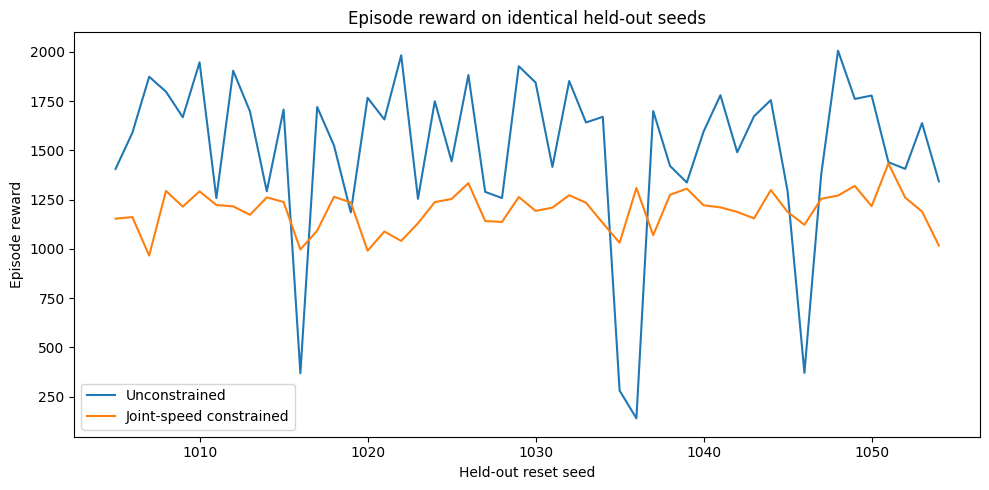

In [15]:
plt.figure(figsize=(10, 5))
plt.plot(
    episode_table["seed"],
    episode_table["unconstrained_reward"],
    label="Unconstrained",
)
plt.plot(
    episode_table["seed"],
    episode_table["joint_constrained_reward"],
    label="Joint-speed constrained",
)
plt.xlabel("Held-out reset seed")
plt.ylabel("Episode reward")
plt.title("Episode reward on identical held-out seeds")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT / "episode_reward_comparison.png", dpi=160)
plt.show()

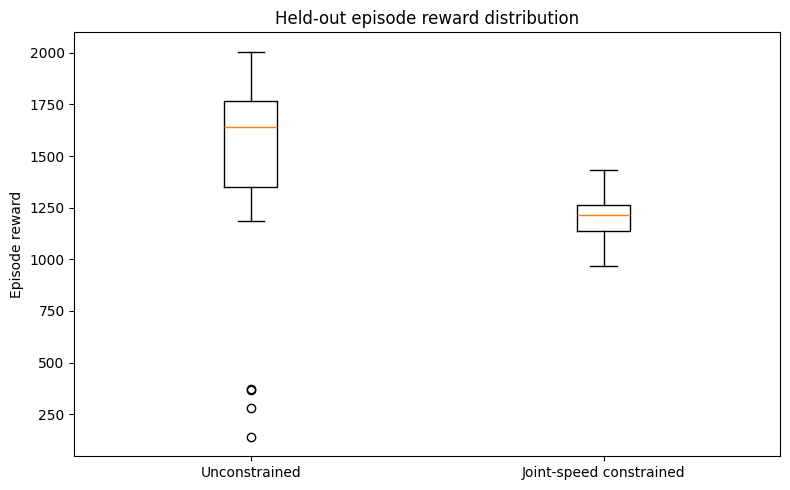

In [16]:
plt.figure(figsize=(8, 5))
plt.boxplot(
    [
        unconstrained["episode_rewards"],
        joint_constrained["episode_rewards"],
    ],
    tick_labels=["Unconstrained", "Joint-speed constrained"],
)
plt.ylabel("Episode reward")
plt.title("Held-out episode reward distribution")
plt.tight_layout()
plt.savefig(OUTPUT / "reward_boxplot.png", dpi=160)
plt.show()

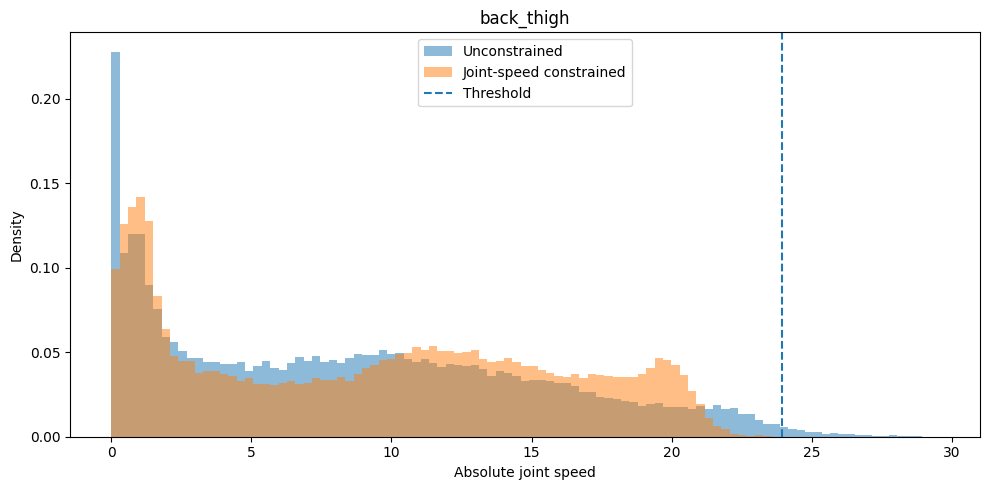

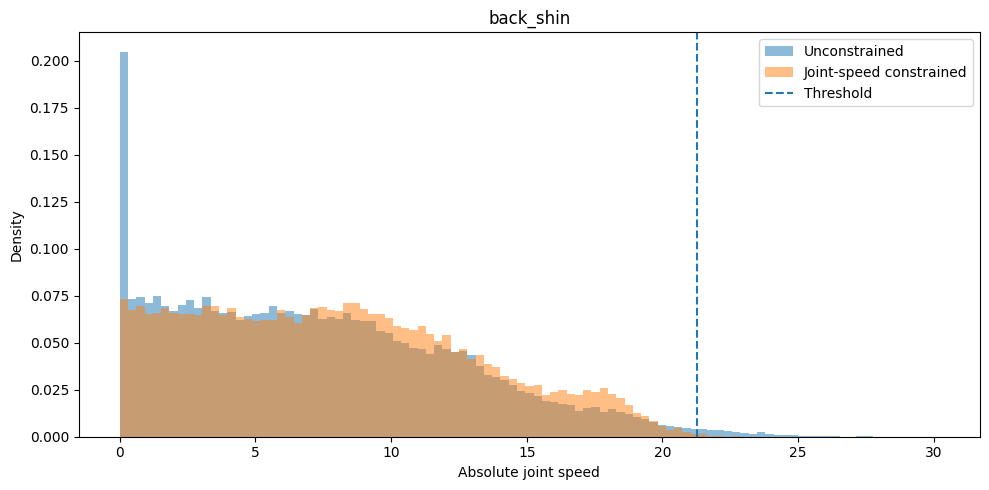

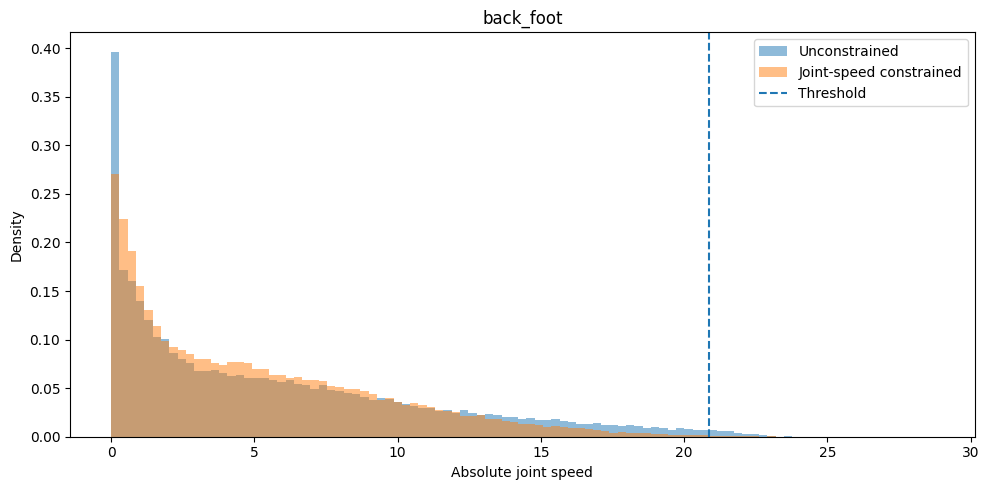

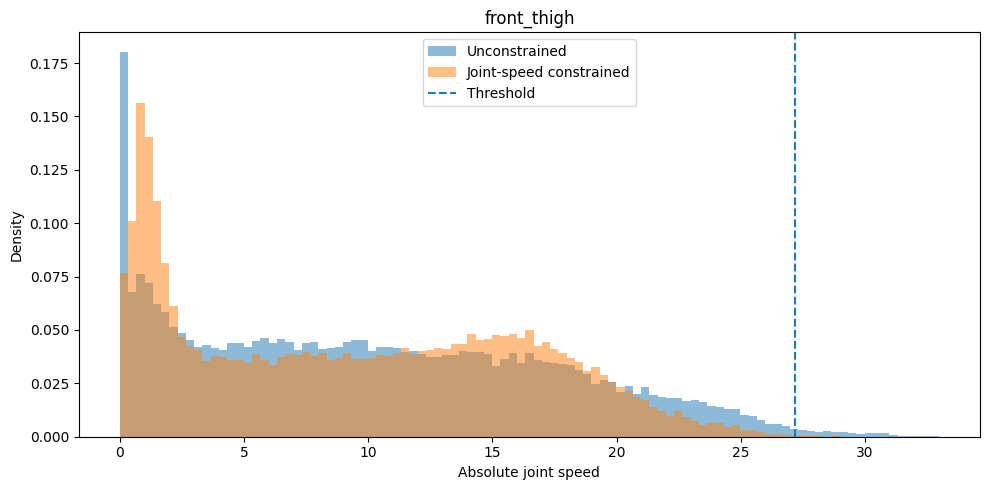

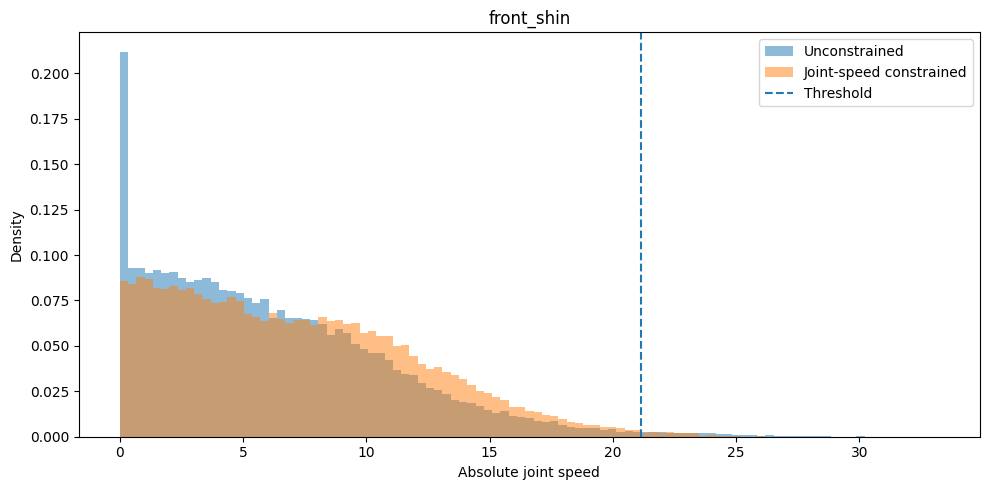

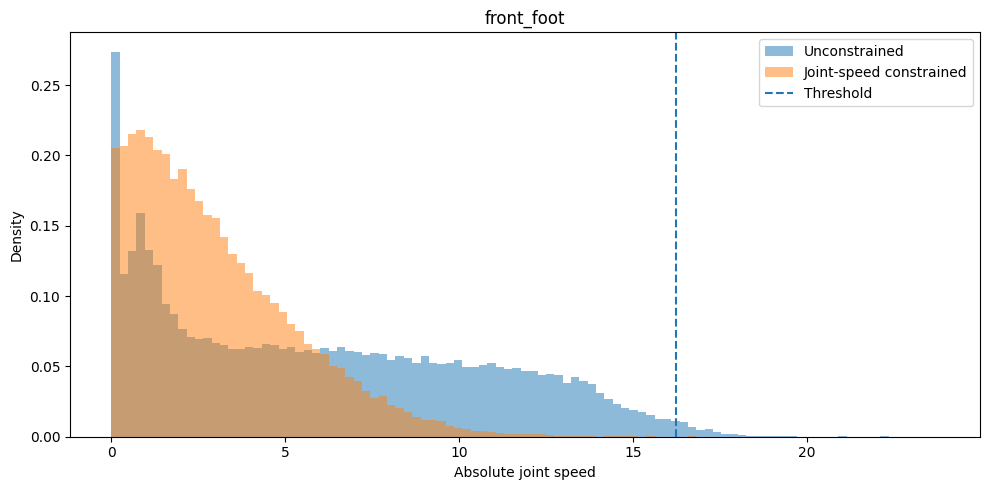

In [17]:
for i, name in enumerate(JOINT_NAMES):
    low = min(
        float(np.min(unconstrained["joint_speeds"][:, i])),
        float(np.min(joint_constrained["joint_speeds"][:, i])),
    )
    high = max(
        float(np.max(unconstrained["joint_speeds"][:, i])),
        float(np.max(joint_constrained["joint_speeds"][:, i])),
    )

    bins = np.linspace(low, high, 100)

    plt.figure(figsize=(10, 5))
    plt.hist(
        unconstrained["joint_speeds"][:, i],
        bins=bins,
        density=True,
        alpha=0.5,
        label="Unconstrained",
    )
    plt.hist(
        joint_constrained["joint_speeds"][:, i],
        bins=bins,
        density=True,
        alpha=0.5,
        label="Joint-speed constrained",
    )
    plt.axvline(
        joint_thresholds[i],
        linestyle="--",
        label="Threshold",
    )
    plt.xlabel("Absolute joint speed")
    plt.ylabel("Density")
    plt.title(name)
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT / f"{name}_speed_distribution.png", dpi=160)
    plt.show()

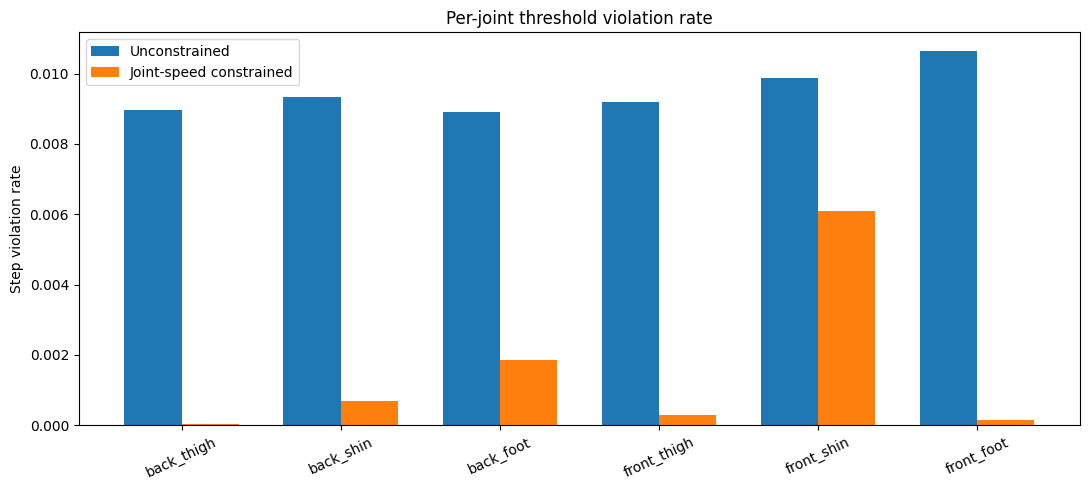

In [18]:
x = np.arange(6)
width = 0.36

u_rates = unconstrained_joint_stats["step_violation_rate"].to_numpy()
c_rates = constrained_joint_stats["step_violation_rate"].to_numpy()

plt.figure(figsize=(11, 5))
plt.bar(x - width / 2, u_rates, width, label="Unconstrained")
plt.bar(x + width / 2, c_rates, width, label="Joint-speed constrained")
plt.xticks(x, JOINT_NAMES, rotation=25)
plt.ylabel("Step violation rate")
plt.title("Per-joint threshold violation rate")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT / "per_joint_step_violation_rates.png", dpi=160)
plt.show()

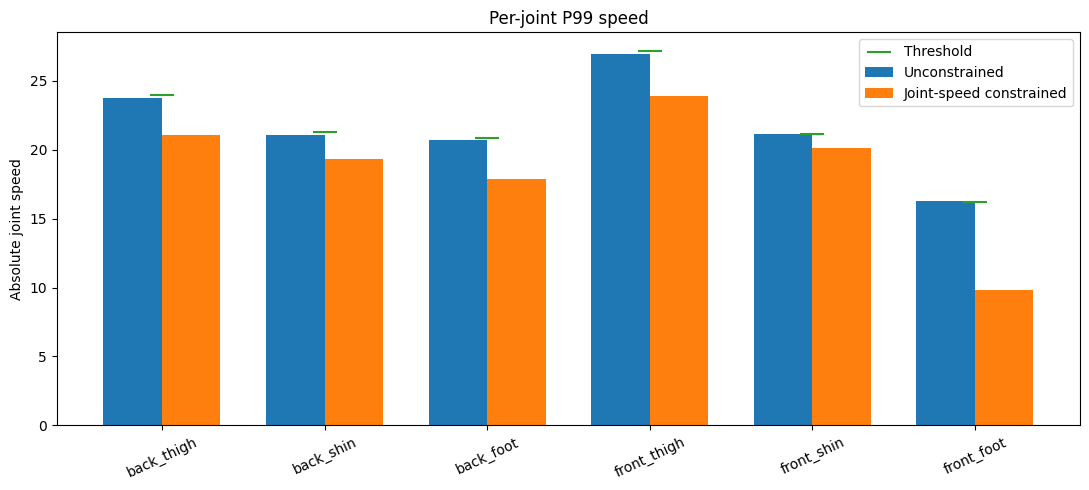

In [19]:
x = np.arange(6)
width = 0.36

u_p99 = unconstrained_joint_stats["p99"].to_numpy()
c_p99 = constrained_joint_stats["p99"].to_numpy()

plt.figure(figsize=(11, 5))
plt.bar(x - width / 2, u_p99, width, label="Unconstrained")
plt.bar(x + width / 2, c_p99, width, label="Joint-speed constrained")
plt.scatter(x, joint_thresholds, marker="_", s=300, label="Threshold")
plt.xticks(x, JOINT_NAMES, rotation=25)
plt.ylabel("Absolute joint speed")
plt.title("Per-joint P99 speed")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT / "per_joint_p99.png", dpi=160)
plt.show()

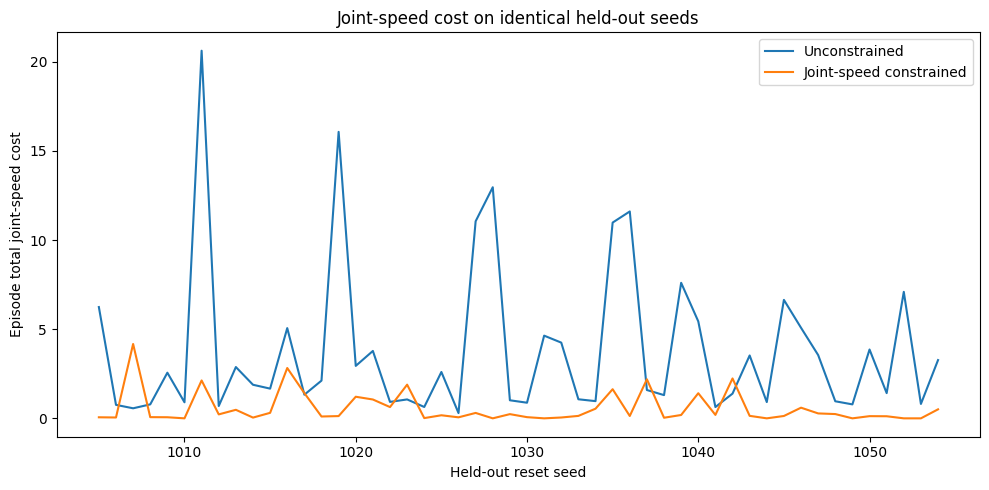

In [20]:
plt.figure(figsize=(10, 5))
plt.plot(
    episode_table["seed"],
    episode_table["unconstrained_total_cost"],
    label="Unconstrained",
)
plt.plot(
    episode_table["seed"],
    episode_table["joint_constrained_total_cost"],
    label="Joint-speed constrained",
)
plt.xlabel("Held-out reset seed")
plt.ylabel("Episode total joint-speed cost")
plt.title("Joint-speed cost on identical held-out seeds")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT / "episode_total_cost_comparison.png", dpi=160)
plt.show()

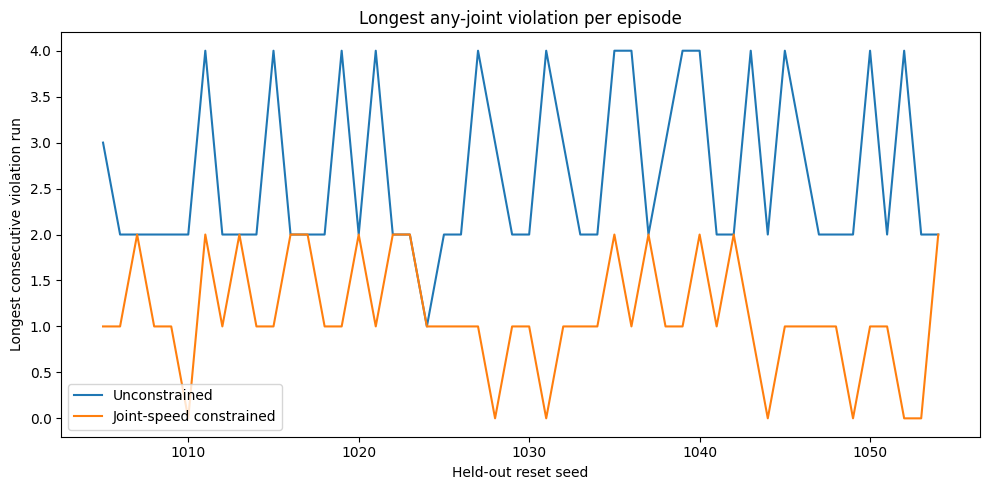

In [21]:
plt.figure(figsize=(10, 5))
plt.plot(
    episode_table["seed"],
    episode_table["unconstrained_longest_violation_run"],
    label="Unconstrained",
)
plt.plot(
    episode_table["seed"],
    episode_table["joint_constrained_longest_violation_run"],
    label="Joint-speed constrained",
)
plt.xlabel("Held-out reset seed")
plt.ylabel("Longest consecutive violation run")
plt.title("Longest any-joint violation per episode")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT / "violation_run_comparison.png", dpi=160)
plt.show()

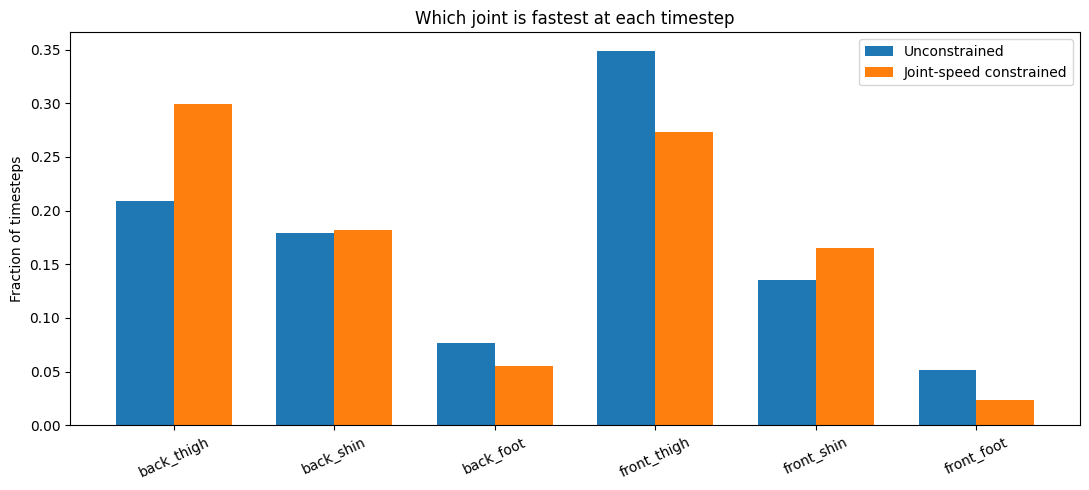

In [22]:
u_fast = np.bincount(
    unconstrained["fastest_joint_index"],
    minlength=6,
).astype(np.float64)

c_fast = np.bincount(
    joint_constrained["fastest_joint_index"],
    minlength=6,
).astype(np.float64)

u_fast /= np.sum(u_fast)
c_fast /= np.sum(c_fast)

x = np.arange(6)
width = 0.36

plt.figure(figsize=(11, 5))
plt.bar(x - width / 2, u_fast, width, label="Unconstrained")
plt.bar(x + width / 2, c_fast, width, label="Joint-speed constrained")
plt.xticks(x, JOINT_NAMES, rotation=25)
plt.ylabel("Fraction of timesteps")
plt.title("Which joint is fastest at each timestep")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT / "fastest_joint_frequency.png", dpi=160)
plt.show()

In [23]:
def worst_episode_by_cost(data):
    index = int(np.argmax(data["episode_costs"]))
    episode_number = index + 1
    seed = int(data["reset_seed"][data["episode"] == episode_number][0])
    return episode_number, seed


u_worst_episode, u_worst_seed = worst_episode_by_cost(unconstrained)
j_worst_episode, j_worst_seed = worst_episode_by_cost(joint_constrained)

print("Unconstrained worst cost episode:", u_worst_episode, "seed:", u_worst_seed)
print("Joint-speed constrained worst cost episode:", j_worst_episode, "seed:", j_worst_seed)

Unconstrained worst cost episode: 7 seed: 1011
Joint-speed constrained worst cost episode: 3 seed: 1007


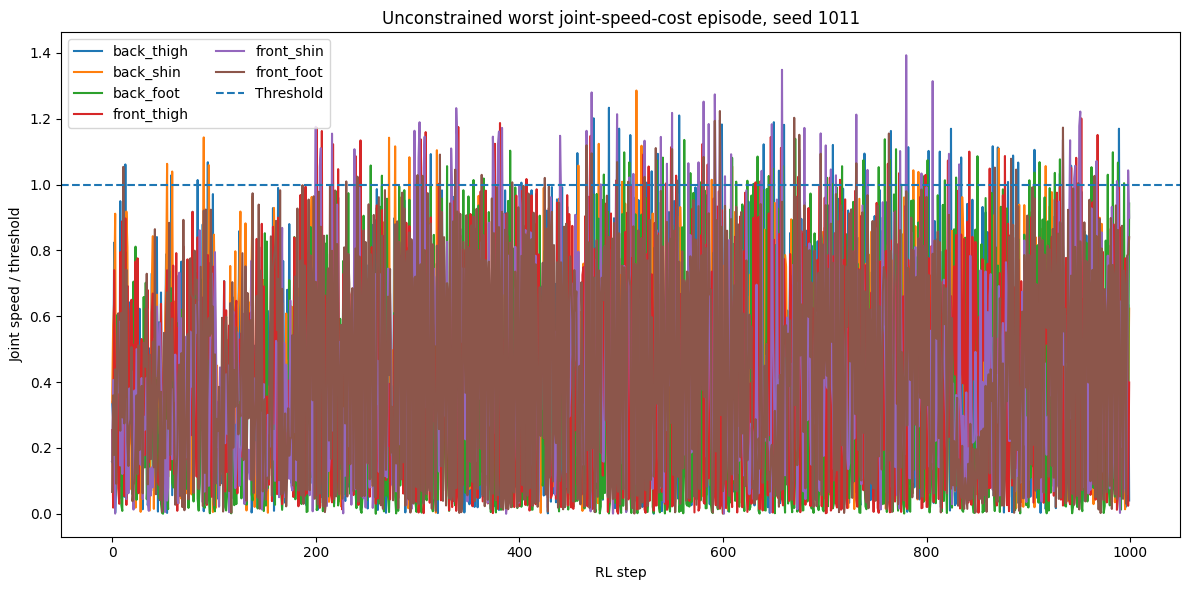

In [24]:
mask = unconstrained["episode"] == u_worst_episode

plt.figure(figsize=(12, 6))

for i, name in enumerate(JOINT_NAMES):
    plt.plot(
        unconstrained["step"][mask],
        unconstrained["joint_speeds"][mask, i] / joint_thresholds[i],
        label=name,
    )

plt.axhline(1.0, linestyle="--", label="Threshold")
plt.xlabel("RL step")
plt.ylabel("Joint speed / threshold")
plt.title(f"Unconstrained worst joint-speed-cost episode, seed {u_worst_seed}")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig(OUTPUT / "unconstrained_worst_joint_speed_episode.png", dpi=160)
plt.show()

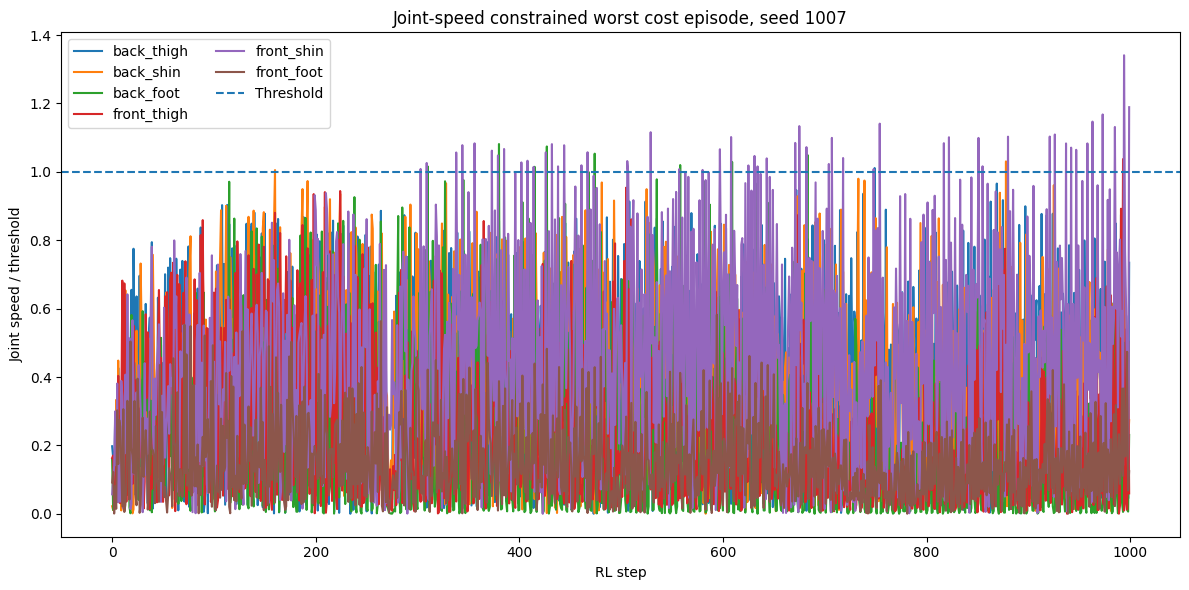

In [25]:
mask = joint_constrained["episode"] == j_worst_episode

plt.figure(figsize=(12, 6))

for i, name in enumerate(JOINT_NAMES):
    plt.plot(
        joint_constrained["step"][mask],
        joint_constrained["joint_speeds"][mask, i] / joint_thresholds[i],
        label=name,
    )

plt.axhline(1.0, linestyle="--", label="Threshold")
plt.xlabel("RL step")
plt.ylabel("Joint speed / threshold")
plt.title(f"Joint-speed constrained worst cost episode, seed {j_worst_seed}")
plt.legend(ncol=2)
plt.tight_layout()
plt.savefig(OUTPUT / "joint_constrained_worst_joint_speed_episode.png", dpi=160)
plt.show()

In [26]:
TRAINING_DATA = PROJECT / "data_train" / "HalfCheetahJointSpeedCost" / f"run{RUN}"

reward_history_path = TRAINING_DATA / "evaluate_rewards.npy"
cost_history_path = TRAINING_DATA / "evaluate_costs.npy"
max_cost_history_path = TRAINING_DATA / "evaluate_max_costs.npy"

training_histories_exist = (
    reward_history_path.exists()
    and cost_history_path.exists()
    and max_cost_history_path.exists()
)

print("Training histories found:", training_histories_exist)
print("Training data directory:", TRAINING_DATA)

Training histories found: True
Training data directory: /home/bannanakid/RCRL_on_RCMDP/data_train/HalfCheetahJointSpeedCost/run1


In [27]:
if training_histories_exist:
    evaluation_rewards = np.load(reward_history_path)
    evaluation_costs = np.load(cost_history_path)
    evaluation_max_costs = np.load(max_cost_history_path)
    evaluation_episode = np.arange(len(evaluation_rewards)) * EVALUATE_FREQ

    print("Evaluation checkpoints:", len(evaluation_rewards))
    print("Last five rewards:", evaluation_rewards[-5:])
    print("Last five total costs:", evaluation_costs[-5:])
    print("Last five maximum costs:", evaluation_max_costs[-5:])

Evaluation checkpoints: 80
Last five rewards: [1035.63744856 1465.96230216 1247.52332651 1491.59092388 1387.1595376 ]
Last five total costs: [1.36561101 1.81650823 1.61026766 2.15518355 1.7668581 ]
Last five maximum costs: [0.34485525 0.30500156 0.21783205 0.19678238 0.53076822]


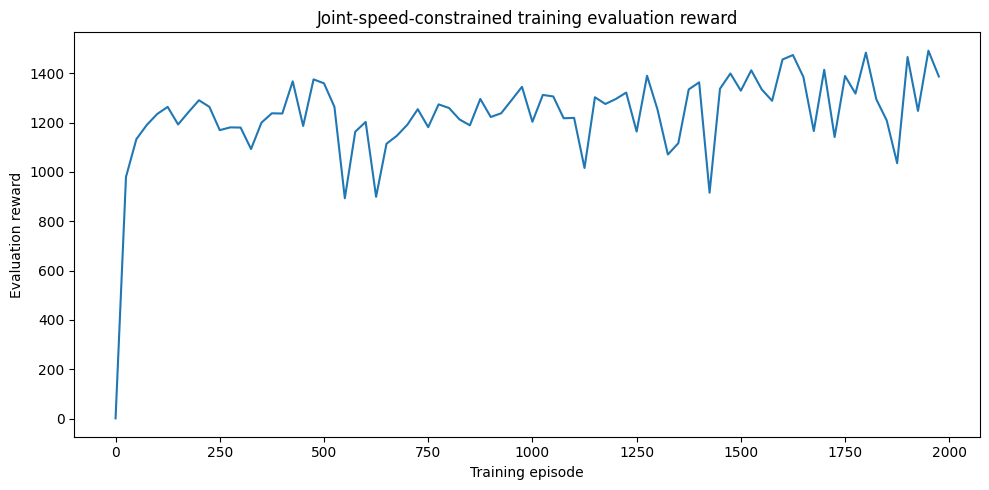

In [28]:
if training_histories_exist:
    plt.figure(figsize=(10, 5))
    plt.plot(evaluation_episode, evaluation_rewards)
    plt.xlabel("Training episode")
    plt.ylabel("Evaluation reward")
    plt.title("Joint-speed-constrained training evaluation reward")
    plt.tight_layout()
    plt.savefig(OUTPUT / "training_evaluation_reward.png", dpi=160)
    plt.show()

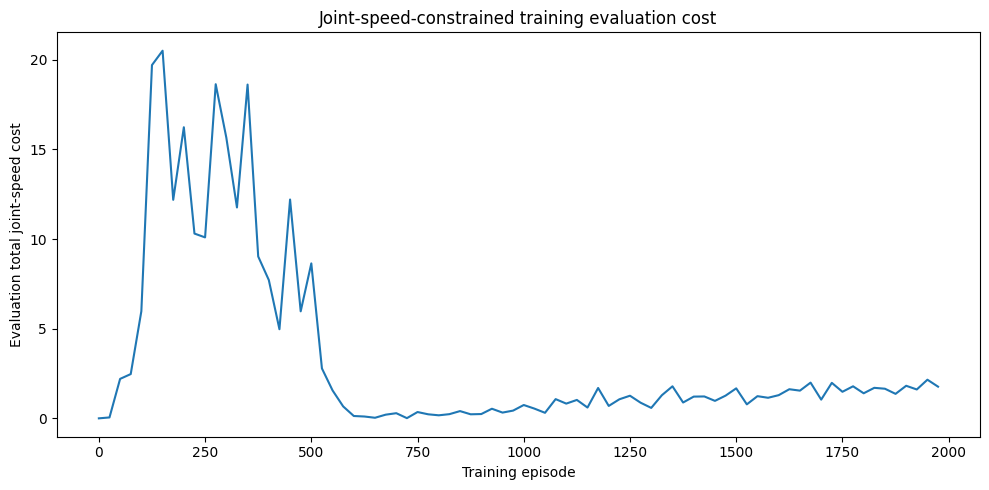

In [29]:
if training_histories_exist:
    plt.figure(figsize=(10, 5))
    plt.plot(evaluation_episode, evaluation_costs)
    plt.xlabel("Training episode")
    plt.ylabel("Evaluation total joint-speed cost")
    plt.title("Joint-speed-constrained training evaluation cost")
    plt.tight_layout()
    plt.savefig(OUTPUT / "training_evaluation_cost.png", dpi=160)
    plt.show()

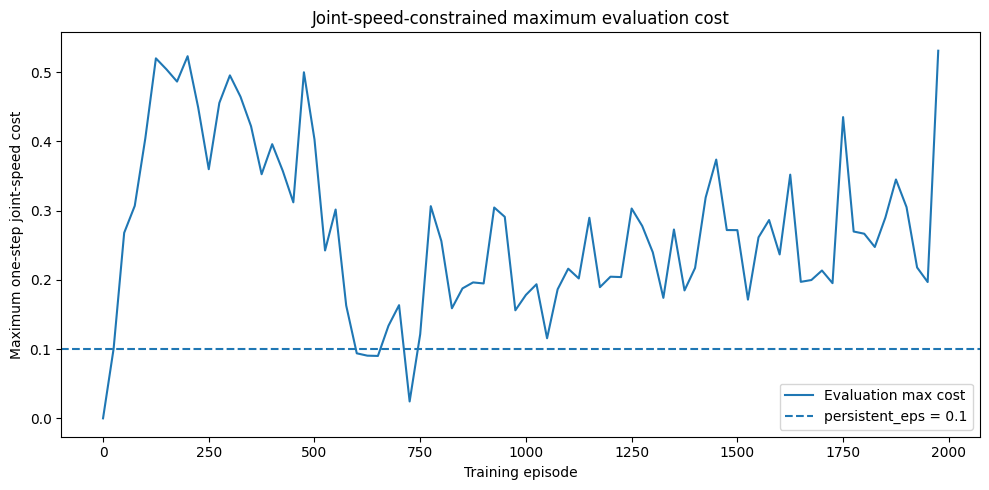

In [30]:
if training_histories_exist:
    plt.figure(figsize=(10, 5))
    plt.plot(
        evaluation_episode,
        evaluation_max_costs,
        label="Evaluation max cost",
    )
    plt.axhline(
        0.1,
        linestyle="--",
        label="persistent_eps = 0.1",
    )
    plt.xlabel("Training episode")
    plt.ylabel("Maximum one-step joint-speed cost")
    plt.title("Joint-speed-constrained maximum evaluation cost")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT / "training_evaluation_max_cost.png", dpi=160)
    plt.show()

In [31]:
final_result = pd.DataFrame(
    [
        {
            "metric": "Mean episode reward",
            "unconstrained": unconstrained_summary["mean_episode_reward"],
            "joint_speed_constrained": joint_summary["mean_episode_reward"],
        },
        {
            "metric": "Mean episode total joint-speed cost",
            "unconstrained": unconstrained_summary["mean_episode_total_cost"],
            "joint_speed_constrained": joint_summary["mean_episode_total_cost"],
        },
        {
            "metric": "Maximum one-step joint-speed cost",
            "unconstrained": unconstrained_summary["maximum_one_step_cost"],
            "joint_speed_constrained": joint_summary["maximum_one_step_cost"],
        },
        {
            "metric": "Overall step violation rate",
            "unconstrained": unconstrained_summary["overall_step_violation_rate"],
            "joint_speed_constrained": joint_summary["overall_step_violation_rate"],
        },
        {
            "metric": "Overall episode violation frequency",
            "unconstrained": unconstrained_summary["overall_episode_violation_frequency"],
            "joint_speed_constrained": joint_summary["overall_episode_violation_frequency"],
        },
        {
            "metric": "Longest violation run",
            "unconstrained": unconstrained_summary["longest_violation_run"],
            "joint_speed_constrained": joint_summary["longest_violation_run"],
        },
        {
            "metric": "Maximum joint speed",
            "unconstrained": unconstrained_summary["maximum_joint_speed"],
            "joint_speed_constrained": joint_summary["maximum_joint_speed"],
        },
        {
            "metric": "Mean net displacement",
            "unconstrained": unconstrained_summary["mean_net_displacement"],
            "joint_speed_constrained": joint_summary["mean_net_displacement"],
        },
    ]
)

final_result["absolute_change"] = (
    final_result["joint_speed_constrained"]
    - final_result["unconstrained"]
)

final_result["percent_change"] = np.where(
    np.abs(final_result["unconstrained"]) > 1e-12,
    100.0
    * final_result["absolute_change"]
    / np.abs(final_result["unconstrained"]),
    np.nan,
)

final_result.to_csv(
    OUTPUT / "final_heldout_result.csv",
    index=False,
)

display(final_result)

print()
print(f"Reward retention: {reward_retention:.2f}%")
print(f"Overall step violation reduction: {step_violation_reduction:.2f}%")
print(f"Overall episode violation-frequency reduction: {episode_violation_reduction:.2f}%")
print(f"Mean episode joint-speed-cost reduction: {total_cost_reduction:.2f}%")
print(f"Maximum one-step cost reduction: {max_cost_reduction:.2f}%")
print("Output directory:", OUTPUT)

,metric,unconstrained,joint_speed_constrained,absolute_change,percent_change
0,Mean episode reward,1503.047712,1195.282592,-307.765120,-20.476071
1,Mean episode total joint-speed cost,3.832063,0.571233,-3.260830,-85.093333
2,Maximum one-step joint-speed cost,0.570787,0.360013,-0.210774,-36.926957
3,Overall step violation rate,0.053660,0.009120,-0.044540,-83.004100
4,Overall episode violation frequency,1.000000,0.860000,-0.140000,-14.000000
5,Longest violation run,4.000000,2.000000,-2.000000,-50.000000
6,Maximum joint speed,33.235771,28.923668,-4.312103,-12.974284
7,Mean net displacement,57.748603,4.559122,-53.189481,-92.105225



Reward retention: 79.52%
Overall step violation reduction: 83.00%
Overall episode violation-frequency reduction: 14.00%
Mean episode joint-speed-cost reduction: 85.09%
Maximum one-step cost reduction: 36.93%
Output directory: /home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahJointSpeedCost/run1/evaluation
